In [1]:
import os
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG19
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from mealpy.swarm_based.GWO import OriginalGWO
print("Semua library berhasil di-import.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.1/149.1 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 397.9/397.9 kB 5.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 22.0 MB/s eta 0:00:0000:0100:01


2025-06-21 11:10:43.926572: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1750504244.224060      75 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1750504244.298461      75 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Semua library berhasil di-import.


In [2]:
# Path ke dataset
DATA_PATH = "/kaggle/input/cell-images-for-detecting-malaria/cell_images/cell_images/"
CATEGORIES = ["Parasitized", "Uninfected"]
IMG_SIZE = 128 

In [3]:
def load_data():
    data = []
    labels = []
    for category in CATEGORIES:
        path = os.path.join(DATA_PATH, category)
        class_num = CATEGORIES.index(category)
        
        for img_name in os.listdir(path):
            if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                try:
                    img_path = os.path.join(path, img_name)
                    img = cv2.imread(img_path)
                    
                    # Pemeriksaan tambahan jika file gambar korup
                    if img is not None:
                        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                        img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
                        data.append(img_resized)
                        labels.append(class_num)
                except Exception as e:
                    print(f"Error reading valid image file {img_path}: {e}")
            
    return np.array(data), np.array(labels)

images, labels = load_data()

images = images.astype('float32') / 255.0

print(f"Data berhasil dimuat.")
print(f"Bentuk data gambar: {images.shape}")
print(f"Bentuk data label: {labels.shape}")
print(f"Jumlah gambar Parasitized: {np.sum(labels == 0)}")
print(f"Jumlah gambar Uninfected: {np.sum(labels == 1)}")

Data berhasil dimuat.
Bentuk data gambar: (27558, 128, 128, 3)
Bentuk data label: (27558,)
Jumlah gambar Parasitized: 13779
Jumlah gambar Uninfected: 13779


In [4]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    images, labels, test_size=0.20, random_state=42, stratify=labels
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.20, random_state=42, stratify=y_train_val
)


print(f"Ukuran data training: {X_train.shape[0]}")
print(f"Ukuran data validasi: {X_val.shape[0]}")
print(f"Ukuran data testing: {X_test.shape[0]}")

Ukuran data training: 17636
Ukuran data validasi: 4410
Ukuran data testing: 5512


In [5]:
datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)

In [6]:
def create_vgg19_model(learning_rate, dropout_rate, dense_units, unfreeze_layers):
    """
    Fungsi untuk membuat model VGG19 yang dapat dikonfigurasi.
    
    Args:
        learning_rate (float): Laju pembelajaran untuk optimizer.
        dropout_rate (float): Rate untuk layer Dropout.
        dense_units (int): Jumlah neuron di layer Dense tersembunyi.
        unfreeze_layers (int): Jumlah layer terakhir dari VGG19 yang akan di-"unfreeze" (dilatih ulang).
        
    Returns:
        model (tf.keras.Model): Model Keras yang sudah di-compile.
    """
    # Load VGG19 base model, tanpa classifier-nya (include_top=False)
    base_model = VGG19(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    
    # Bekukan semua layer di base model pada awalnya
    for layer in base_model.layers:
        layer.trainable = False
        
    # Unfreeze N layer terakhir dari base model
    if unfreeze_layers > 0:
        for layer in base_model.layers[-unfreeze_layers:]:
            layer.trainable = True
            
    # Tambahkan layer classifier kustom di atas base model
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(dense_units, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    predictions = Dense(1, activation='sigmoid')(x) # Output biner (Parasitized/Uninfected)
    
    model = Model(inputs=base_model.input, outputs=predictions)
    
    # Compile model
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    
    return model

In [8]:
from mealpy.utils.space import FloatVar, IntegerVar
import gc
import json # <-- Import library untuk menyimpan file

def objective_function(solution):
    lr, dropout, dense_idx, unfreeze_idx = solution
    dense_units_options = [128, 256, 512]
    unfreeze_layers_options = [0, 5, 10, 15]
    dense_units = dense_units_options[int(np.round(dense_idx))]
    unfreeze_layers = unfreeze_layers_options[int(np.round(unfreeze_idx))]
    model = create_vgg19_model(
        learning_rate=lr,
        dropout_rate=dropout,
        dense_units=dense_units,
        unfreeze_layers=unfreeze_layers
    )
    history = model.fit(
        datagen.flow(X_train, y_train, batch_size=32),
        validation_data=(X_val, y_val),
        epochs=3,
        verbose=0
    )
    val_accuracy = np.max(history.history['val_accuracy'])
    print(f"Testing HP: lr={lr:.5f}, dropout={dropout:.2f}, dense={dense_units}, unfreeze={unfreeze_layers} -> Val Acc: {val_accuracy:.4f}")
    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return 1.0 - val_accuracy

bounds = [
    FloatVar(lb=1e-5, ub=1e-3, name="learning_rate"),
    FloatVar(lb=0.2, ub=0.7, name="dropout_rate"),
    IntegerVar(lb=0, ub=2, name="dense_units_index"),
    IntegerVar(lb=0, ub=3, name="unfreeze_layers_index"),
]
problem_dict = {
    "obj_func": objective_function,
    "bounds": bounds,
    "minmax": "min",
}

gwo_epochs = 5
gwo_pop_size = 5

print("\nMemulai Optimasi GWO dengan format problem yang BENAR...")
model_gwo = OriginalGWO(epoch=gwo_epochs, pop_size=gwo_pop_size)
best_agent = model_gwo.solve(problem_dict)

best_position = best_agent.solution
best_fitness = best_agent.target.fitness 

print(f"\nOptimasi GWO Selesai.")
print(f"Fitness (1 - val_acc) terbaik: {best_fitness}")
print(f"Solusi (hyperparameter) terbaik: {best_position}")

best_lr = best_position[0]
best_dropout = best_position[1]
best_dense_units = [128, 256, 512][int(np.round(best_position[2]))]
best_unfreeze_layers = [0, 5, 10, 15][int(np.round(best_position[3]))]

print("\n--- Hyperparameter Terbaik Ditemukan ---")
print(f"Learning Rate: {best_lr:.6f}")
print(f"Dropout Rate: {best_dropout:.3f}")
print(f"Dense Units: {best_dense_units}")
print(f"Unfreeze Layers: {best_unfreeze_layers}")

print("\nMenyimpan hyperparameter terbaik ke file...")
best_hyperparameters = {
    "best_lr": best_lr,
    "best_dropout": best_dropout,
    "best_dense_units": int(best_dense_units),
    "best_unfreeze_layers": int(best_unfreeze_layers)
}

with open('best_hyperparameters.json', 'w') as f:
    json.dump(best_hyperparameters, f, indent=4)

print("Hyperparameter berhasil disimpan di file 'best_hyperparameters.json'.")
# =================================================================


Memulai Optimasi GWO dengan format problem yang BENAR...


I0000 00:00:1750504584.175495      75 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1750504593.215190     137 service.cc:148] XLA service 0x7ec2e4003780 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1750504593.216437     137 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1750504593.883663     137 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1750504600.069413     137 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Testing HP: lr=0.00021, dropout=0.62, dense=512, unfreeze=10 -> Val Acc: 0.5000
Testing HP: lr=0.00016, dropout=0.38, dense=512, unfreeze=0 -> Val Acc: 0.8780
Testing HP: lr=0.00015, dropout=0.30, dense=256, unfreeze=10 -> Val Acc: 0.9544
Testing HP: lr=0.00021, dropout=0.49, dense=512, unfreeze=0 -> Val Acc: 0.8748
Testing HP: lr=0.00008, dropout=0.50, dense=128, unfreeze=5 -> Val Acc: 0.9528
Testing HP: lr=0.00020, dropout=0.45, dense=256, unfreeze=10 -> Val Acc: 0.5000
Testing HP: lr=0.00007, dropout=0.65, dense=128, unfreeze=0 -> Val Acc: 0.8204
Testing HP: lr=0.00012, dropout=0.44, dense=256, unfreeze=0 -> Val Acc: 0.8408
Testing HP: lr=0.00012, dropout=0.37, dense=128, unfreeze=5 -> Val Acc: 0.9544
Testing HP: lr=0.00013, dropout=0.55, dense=256, unfreeze=5 -> Val Acc: 0.9519
Testing HP: lr=0.00011, dropout=0.54, dense=256, unfreeze=5 -> Val Acc: 0.9533
Testing HP: lr=0.00008, dropout=0.44, dense=256, unfreeze=5 -> Val Acc: 0.9549
Testing HP: lr=0.00003, dropout=0.34, dense=256, 

In [9]:
print("\n--- Memulai Pelatihan Model Final dengan Hyperparameter Terbaik ---")

final_model = create_vgg19_model(
    learning_rate=best_lr,
    dropout_rate=best_dropout,
    dense_units=best_dense_units,
    unfreeze_layers=best_unfreeze_layers
)

print("\nArsitektur Model Final:")
final_model.summary()

early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
model_checkpoint = ModelCheckpoint('malaria_vgg19_best.h5', monitor='val_accuracy', save_best_only=True, verbose=1)

BATCH_SIZE = 32
EPOCHS = 25 

print("\nMemulai proses fit pada model final...")
# Latih model
history = final_model.fit(
    datagen.flow(X_train, y_train, batch_size=BATCH_SIZE),
    steps_per_epoch=len(X_train) // BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, model_checkpoint]
)

print("\nPelatihan Model Final Selesai.")


--- Memulai Pelatihan Model Final dengan Hyperparameter Terbaik ---

Arsitektur Model Final:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 128, 128, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 128, 128, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 64, 64, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 64, 64, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 64, 64, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 32, 32, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 32, 32, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 32, 32, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 32, 32, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv4 (Conv2D)                │ (None, 32, 32, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 16, 16, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 16, 16, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 16, 16, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 16, 16, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv4 (Conv2D)                │ (None, 16, 16, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 8, 8, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 8, 8, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 8, 8, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 8, 8, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv4 (Conv2D)                │ (None, 8, 8, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 20,155,969 (76.89 MB)

 Trainable params: 9,570,817 (36.51 MB)

 Non-trainable params: 10,585,152 (40.38 MB)


Memulai proses fit pada model final...
Epoch 1/50
551/551 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.8693 - loss: 0.3024
Epoch 1: val_accuracy improved from -inf to 0.94830, saving model to malaria_vgg19_best.h5
551/551 ━━━━━━━━━━━━━━━━━━━━ 75s 128ms/step - accuracy: 0.8694 - loss: 0.3023 - val_accuracy: 0.9483 - val_loss: 0.1547
Epoch 2/50
  1/551 ━━━━━━━━━━━━━━━━━━━━ 25s 47ms/step - accuracy: 0.9375 - loss: 0.1349

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:107: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_accuracy improved from 0.94830 to 0.94921, saving model to malaria_vgg19_best.h5
551/551 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9375 - loss: 0.1349 - val_accuracy: 0.9492 - val_loss: 0.1533
Epoch 3/50
551/551 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.9426 - loss: 0.1663
Epoch 3: val_accuracy improved from 0.94921 to 0.95283, saving model to malaria_vgg19_best.h5
551/551 ━━━━━━━━━━━━━━━━━━━━ 67s 121ms/step - accuracy: 0.9426 - loss: 0.1663 - val_accuracy: 0.9528 - val_loss: 0.1367
Epoch 4/50
  1/551 ━━━━━━━━━━━━━━━━━━━━ 25s 46ms/step - accuracy: 1.0000 - loss: 0.0497
Epoch 4: val_accuracy did not improve from 0.95283
551/551 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 1.0000 - loss: 0.0497 - val_accuracy: 0.9524 - val_loss: 0.1389
Epoch 5/50
551/551 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.9469 - loss: 0.1578
Epoch 5: val_accuracy did not improve from 0.95283
551/551 ━━━━━━━━━━━━━━━━━━━━ 67s 121ms/step - accuracy: 0.9469 - loss: 0.1578 - val_accurac

In [10]:
print("\n--- Memulai Pelatihan Model Final dengan Hyperparameter Terbaik ---")
print(f"Menggunakan Konfigurasi: LR={best_lr:.6f}, Dropout={best_dropout:.3f}, Dense={best_dense_units}, Unfreeze={best_unfreeze_layers}")

final_model = create_vgg19_model(
    learning_rate=best_lr,
    dropout_rate=best_dropout,
    dense_units=best_dense_units,
    unfreeze_layers=best_unfreeze_layers
)

print("\nArsitektur Model Final:")
final_model.summary()
early_stopping = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True, verbose=1)
model_checkpoint = ModelCheckpoint('malaria_vgg19_best.h5', monitor='val_accuracy', save_best_only=True, verbose=1)

BATCH_SIZE = 32
EPOCHS = 50 

print("\nMemulai proses fit pada model final...")
# Latih model
history = final_model.fit(
    datagen.flow(X_train, y_train, batch_size=BATCH_SIZE),
    steps_per_epoch=len(X_train) // BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, model_checkpoint]
)

print("\nPelatihan Model Final Selesai.")
print("Model terbaik telah disimpan di file 'malaria_vgg19_best.h5'")


--- Memulai Pelatihan Model Final dengan Hyperparameter Terbaik ---
Menggunakan Konfigurasi: LR=0.000100, Dropout=0.494, Dense=256, Unfreeze=5

Arsitektur Model Final:


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 128, 128, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 128, 128, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 64, 64, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 64, 64, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 64, 64, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 32, 32, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 32, 32, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 32, 32, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 32, 32, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv4 (Conv2D)                │ (None, 32, 32, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 16, 16, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 16, 16, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 16, 16, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 16, 16, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv4 (Conv2D)                │ (None, 16, 16, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 8, 8, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 8, 8, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 8, 8, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 8, 8, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv4 (Conv2D)                │ (None, 8, 8, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 20,155,969 (76.89 MB)

 Trainable params: 9,570,817 (36.51 MB)

 Non-trainable params: 10,585,152 (40.38 MB)


Memulai proses fit pada model final...
Epoch 1/50
290/551 ━━━━━━━━━━━━━━━━━━━━ 30s 117ms/step - accuracy: 0.7977 - loss: 0.4081

KeyboardInterrupt: 

Memuat bobot model terbaik dari file 'malaria_vgg19_best.h5' untuk evaluasi...

--- Mengevaluasi Model pada Data Tes ---
173/173 ━━━━━━━━━━━━━━━━━━━━ 8s 42ms/step - accuracy: 0.9594 - loss: 0.1277

Hasil pada Test Set:
Loss: 0.1188
Akurasi: 96.03%

--- Menampilkan Grafik History Pelatihan ---


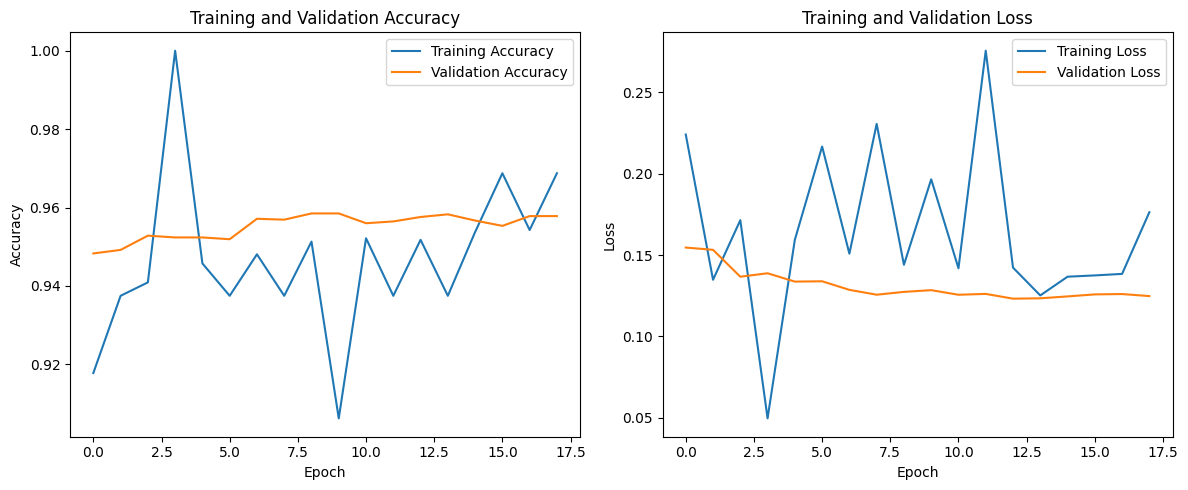


--- Laporan Klasifikasi Rinci dan Confusion Matrix ---
173/173 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step
Classification Report:
              precision    recall  f1-score   support

 Parasitized       0.97      0.95      0.96      2756
  Uninfected       0.95      0.97      0.96      2756

    accuracy                           0.96      5512
   macro avg       0.96      0.96      0.96      5512
weighted avg       0.96      0.96      0.96      5512



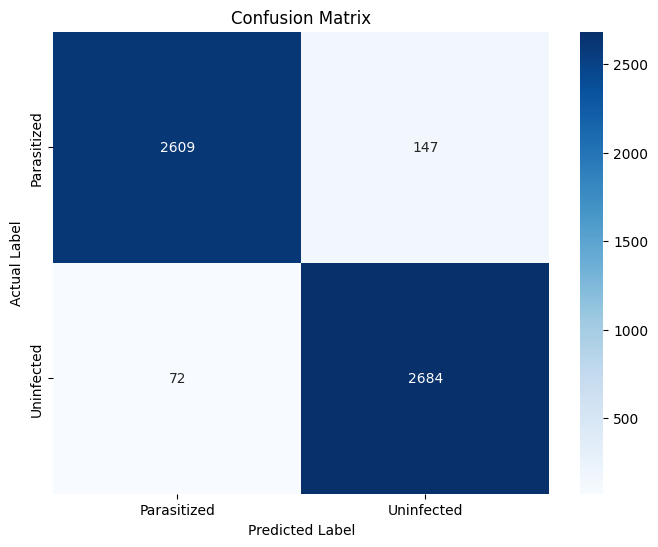

In [11]:
print("Memuat bobot model terbaik dari file 'malaria_vgg19_best.h5' untuk evaluasi...")
final_model.load_weights('malaria_vgg19_best.h5')

print("\n--- Mengevaluasi Model pada Data Tes ---")
loss, accuracy = final_model.evaluate(X_test, y_test, verbose=1)
print(f"\nHasil pada Test Set:")
print(f"Loss: {loss:.4f}")
print(f"Akurasi: {accuracy*100:.2f}%")
print("\n--- Menampilkan Grafik History Pelatihan ---")
plt.figure(figsize=(12, 5))

# Plot Akurasi
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


print("\n--- Laporan Klasifikasi Rinci dan Confusion Matrix ---")
# Buat prediksi pada data tes
y_pred_probs = final_model.predict(X_test)
y_pred_classes = (y_pred_probs > 0.5).astype("int32").reshape(-1)

print("Classification Report:")
print(classification_report(y_test, y_pred_classes, target_names=CATEGORIES))

# Buat dan tampilkan Confusion Matrix
cm = confusion_matrix(y_test, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CATEGORIES,
            yticklabels=CATEGORIES)
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()